# Axion-induced magnetic fields in the Earth–ionosphere system: figure reproduction

This notebook reproduces the figures of

> **Signature of axion dark matter in low-frequency terrestrial electromagnetic fields: formulation and predictions**
> [arXiv:2509.14673](https://arxiv.org/abs/2509.14673) (PTEP)

Axion dark matter, converted to photons in the geomagnetic field, induces an oscillating magnetic field ${\boldsymbol B}_{\rm a}$ in the cavity between the Earth's surface and the ionosphere. The notebook computes its radial mode functions, using a multi-step treatment of the atmospheric conductivity profile, and its amplitude at the Earth's surface.

### Structure

| Section | Content |
|---|---|
| **0. Setup** | imports, options (LaTeX, saving PDFs), input data |
| **1. Common modules** | every function used by the figures, defined once |
| **2. Figures** | Figs. 1, 2, 4–9; each figure depends only on Sections 0 and 1 |

Run Sections 0 and 1 once, then any figure cell can be run on its own, in any order. (Fig. 3 is a schematic diagram, so no code produces it.)

### Requirements

* `numpy`, `scipy` (≥ 1.15, for `scipy.special.sph_harm_y`), `matplotlib`
* `cartopy`: only for the world maps of Fig. 7
* A LaTeX installation, to typeset labels exactly as in the paper. Without LaTeX, the notebook falls back automatically to matplotlib's built-in mathtext.
* IGRF-13 coefficient file `igrf13coeffs.txt` (Figs. 6–9). If it isn't found in `DATA_DIR`, the notebook downloads it from NOAA/NCEI.

### Approximate run times (single core)
Fig. 4: ~15 s, Fig. 6: ~1 min, Fig. 7: ~10 s, Fig. 8: ~20 s, Fig. 9: ~2 min; the other figures take a few seconds.

---
# 0. Setup

In [1]:
import os
import shutil
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MultipleLocator
from scipy.interpolate import interp1d
from scipy.special import spherical_jn, spherical_yn, hankel1, sph_harm_y

try:   # only needed for Fig. 7
    import cartopy.crs as ccrs
    from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("cartopy is not installed: Fig. 7 (world maps) will be skipped.")

In [2]:
# ------------------------------------------------------------------
#  User options
# ------------------------------------------------------------------
DATA_DIR = "./data"          # directory containing the IGRF-13 coefficient file
FIG_DIR  = "./figs"          # output directory for PDF files
SAVE_PDF = False             # True: save every figure as PDF in FIG_DIR

USE_TEX  = None              # True / False, or None = use LaTeX only if it works on this machine

# ------------------------------------------------------------------
def _latex_works():
    """Test-render a label with LaTeX (fails, e.g., if the cm-super fonts are missing)."""
    if shutil.which("latex") is None:
        return False
    try:
        with plt.rc_context({"text.usetex": True}):
            fig = plt.figure()
            fig.text(0.5, 0.5, r"$m_{\rm a}$ [eV]")
            fig.canvas.draw()
        return True
    except Exception:
        return False
    finally:
        plt.close("all")

if USE_TEX is None:
    USE_TEX = _latex_works()
    if not USE_TEX:
        print("LaTeX is not available: labels are typeset with matplotlib's mathtext instead.")
plt.rcParams["text.usetex"] = USE_TEX
if USE_TEX:
    plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}"
BVEC = r"\boldsymbol{B}" if USE_TEX else r"\mathbf{B}"   # bold-face B in axis labels

def save_pdf(fig, filename):
    """Save a figure as PDF in FIG_DIR, if SAVE_PDF is True."""
    if SAVE_PDF:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, filename), bbox_inches="tight")

---
# 1. Common modules

All the physics is in this section. The figure cells in Section 2 only set parameters, call these functions and plot.

| Subsection | Main functions |
|---|---|
| 1.1 Constants and unit conversions | `m2f`, `f2m`, `xx`, `nn2`, `amp_axion` |
| 1.2 Atmospheric conductivity models | `sigma_kudintseva16`, `sigma_nickolaenko16`, `sigma_galuk18`, `step_profile`, `exp_scale_height` |
| 1.3 Radial mode functions (multi-step treatment) | `mode_coeff_surface`, `radial_mode_function`, `mode_coeff_surface_perfect_cond` |
| 1.4 Geomagnetic field (IGRF-13) | `load_igrf`, `cc_nm` |
| 1.5 Vector spherical harmonics | `er`, `etheta`, `ephi`, `vshPhi`, `vsh_sum` |
| 1.6 Axion-induced magnetic field | `site_angles`, `B_surface`, `B_profile`, `horizontal_components` |

## 1.1 Constants and unit conversions

In [3]:
R_EARTH = 6371.2     # Earth radius [km] (IGRF reference radius)
ELL_MAX = 13         # maximum multipole (IGRF-13 is available up to ell = 13)

def m2f(mass):
    """Axion mass [eV]  ->  frequency [Hz]."""
    return 0.24 * mass / 1e-15

def f2m(freq):
    """Frequency [Hz]  ->  axion mass [eV]."""
    return freq * 1e-15 / 0.24

def xx(r, mass, RE=R_EARTH):
    """Dimensionless radius x = m_a r  (r in km; 0.032 = m_a R_E for m_a = 1e-15 eV)."""
    return 0.032 * (mass / 1e-15) * r / RE

def nn2(sigma, mass):
    """Squared refractive index n^2 = 1 + i sigma/omega for conductivity sigma [S/m]."""
    return 1 + 1j * 0.74 * (sigma / 1e-10) * (1e-14 / mass)

def amp_axion(mass, g_ag=1e-10, rho_DM=0.3):
    """g_{a gamma} * a_0, assuming that the axion is all of the dark matter.
       g_ag in GeV^-1, rho_DM in GeV/cm^3."""
    return 21.4e-8 * 1e-15 / mass * (g_ag / 1e-10) * np.sqrt(rho_DM / 0.3)

## 1.2 Atmospheric conductivity models

Tabulated conductivity profiles $\sigma(h)$ [S/m] as a function of altitude $h=r-R_{\rm E}$ [km]:

* `sigma_kudintseva16`: Kudintseva, Nickolaenko, Rycroft & Odzimek, Ann. Geophys. 34, 5 (2016). **Default model.**
* `sigma_nickolaenko16`: Nickolaenko, Galuk & Hayakawa, SpringerPlus 5, 108 (2016), median profile. [doi:10.1186/s40064-016-1742-3](https://doi.org/10.1186/s40064-016-1742-3)
* `sigma_galuk18`: Galuk, Nickolaenko & Hayakawa, J. Atmos. Sol.-Terr. Phys. (2018), day and night profiles.

In [4]:
def sigma_kudintseva16():
    """Kudintseva et al. (2016).  Returns (h [km], sigma [S/m]),  h = 0--99 km."""
    h = np.linspace(0, 99, 100)
    sigma = np.array([1.512E-14, 2.160E-14, 4.090E-14, 6.962E-14, 1.049E-13, 1.482E-13, 2.019E-13, 2.712E-13, 3.549E-13, 4.651E-13, 5.943E-13, 7.629E-13, 9.578E-13, 1.209E-12, 1.499E-12, 1.867E-12, 2.285E-12, 2.796E-12, 3.375E-12, 4.093E-12, 4.891E-12, 5.864E-12, 6.930E-12, 8.227E-12, 9.634E-12, 1.135E-11, 1.320E-11,1.545E-11, 1.788E-11, 2.085E-11, 2.416E-11, 2.774E-11, 3.164E-11, 3.626E-11, 4.207E-11, 4.925E-11, 5.762E-11, 6.821E-11, 7.947E-11, 9.359E-11, 1.101E-10, 1.3461E-10, 1.555E-10, 1.840E-10, 2.097E-10, 2.410E-10, 2.651E-10, 2.855E-10, 2.991E-10, 3.183E-10, 3.380E-10, 3.514E-10, 3.710E-10, 3.998E-10, 4.299E-10, 5.229E-10, 6.160E-10, 8.044E-10, 9.929E-10, 1.398E-9, 1.803E-9, 2.731E-9, 3.659E-9, 5.896E-9, 8.133E-9, 1.365E-8, 1.916E-8, 3.249E-8, 4.582E-8, 6.887E-8, 9.636E-8, 1.419E-7, 1.893E-7, 2.839E-7, 4.258E-7, 5.678E-7, 7.570E-7, 9.463E-7, 1.183E-6, 1.467E-6, 1.751E-6, 2.176E-6, 2.602E-6, 3.265E-6, 3.927E-6, 5.157E-6, 6.388E-6, 8.895E-6, 1.145E-5, 1.713E-5, 2.285E-5, 3.686E-5, 5.091E-5, 9.042E-5, 1.230E-4, 2.652E-4, 4.005E-4, 9.690E-4, 1.538E-3, 2.338E-3])
    return h, sigma


def sigma_nickolaenko16():
    """Nickolaenko et al. (2016), median profile.  Returns (h [km], sigma [S/m]),  h = 2--98 km.
       (The day/night profiles in the same reference are not used: they look unreliable.)"""
    h = np.linspace(2, 98, 97)
    log_sigma = np.array([-12.77, -12.68, -12.60, -12.51, -12.43, -12.31, -12.22, -12.08, -11.97, -11.84, -11.74, -11.62, -11.53, -11.42, -11.34, -11.25, -11.17, -11.09, -11.02, -10.94, -10.88, -10.80, -10.74, -10.67, -10.61, -10.55, -10.49, -10.42, -10.37, -10.32, -10.28, -10.24, -10.19, -10.14, -10.09, -10.03, -10.00, -9.95,  -9.92,  -9.86,  -9.83,  -9.78,  -9.75,  -9.70,  -9.67,  -9.64,  -9.62,  -9.59,  -9.56,  -9.52,  -9.48, -9.44, -9.40, -9.30, -9.23, -9.11, -9.02, -8.87, -8.75, -8.57, -8.45, -8.24, -8.10, -7.87, -7.73, -7.50, -7.35, -7.17, -7.02, -6.85, -6.72, -6.55, -6.37, -6.25, -6.12, -6.02, -5.93, -5.83, -5.76, -5.66, -5.58, -5.49, -5.40, -5.29, -5.19, -5.05, -4.94, -4.77, -4.64, -4.43, -4.29, -4.04, -3.89, -3.58, -3.40, -3.01, -2.81])
    return h, 10**log_sigma


def sigma_galuk18():
    """Galuk et al. (2018).  Returns (h [km], sigma_day [S/m], sigma_night [S/m]),  h = 0--110 km."""
    h = np.linspace(0, 110, 111)
    log_sigma_day   = np.array([-14.12, -13.97, -13.82, -13.67, -13.40, -13.17, -12.99, -12.84, -12.71, -12.58, -12.46, -12.35, -12.24, -12.13, -12.03, -11.93, -11.84, -11.74, -11.65, -11.57, -11.48, -11.40, -11.32, -11.24, -11.17, -11.10, -11.03, -10.96, -10.89, -10.82, -10.74, -10.65, -10.58, -10.51, -10.44, -10.35, -10.24, -10.16, -10.09, -9.97,  -9.92,  -9.84,  -9.75, -9.69, -9.63, -9.59, -9.56, -9.53, -9.51, -9.48, -9.46, -9.44, -9.40, -9.38, -9.29, -9.22, -9.10, -9.01, -8.86, -8.75, -8.57, -8.45, -8.24, -8.10, -7.87, -7.73, -7.50, -7.35, -7.17, -7.02, -6.85, -6.72, -6.55, -6.37, -6.25, -6.12, -6.02, -5.93, -5.83, -5.76, -5.66, -5.58, -5.49, -5.41, -5.29, -5.19, -5.05, -4.94, -4.77, -4.64, -4.43, -4.29, -4.04, -3.89, -3.58, -3.40, -3.01, -2.81, -2.61, -2.41, -2.21, -2.00, -1.87, -1.72, -1.48, -1.29, -1.13, -0.96, -0.81, -0.67, -0.54])
    log_sigma_night = np.array([-14.12, -13.97, -13.82, -13.67, -13.40, -13.17, -12.99, -12.84, -12.71, -12.58, -12.46, -12.35, -12.24, -12.13, -12.03, -11.93, -11.84, -11.74, -11.65, -11.57, -11.48, -11.40, -11.32, -11.24, -11.17, -11.10, -11.03, -10.96, -10.89, -10.82, -10.76, -10.69, -10.63, -10.57, -10.51, -10.45, -10.39, -10.32, -10.25, -10.18, -10.11, -10.04, -9.99, -9.93, -9.87, -9.81, -9.75, -9.68, -9.64, -9.62, -9.58, -9.57, -9.56, -9.53, -9.51, -9.48, -9.46, -9.44, -9.40, -9.38, -9.29, -9.22, -9.10, -9.01, -8.86, -8.75, -8.57, -8.45, -8.24, -8.10, -7.90, -7.73, -7.50, -7.35, -7.17, -7.02, -6.85, -6.72, -6.55, -6.37, -6.25, -6.12, -6.02, -5.93, -5.83, -5.76, -5.66, -5.58, -5.49, -5.41, -5.29, -5.19, -5.05, -4.94, -4.77, -4.64, -4.43, -4.29, -4.04, -3.89, -3.58, -3.35, -3.15, -3.05, -2.96, -2.88, -2.81, -2.76, -2.71, -2.67, -2.64])
    return h, 10**log_sigma_day, 10**log_sigma_night


def step_profile(h, sigma, num_step=300):
    """Discretize a tabulated profile into num_step layers (cubic interpolation).
       Returns (h_step, sigma_step), each with num_step+1 points."""
    h_step = np.linspace(h[0], h[-1], num_step + 1)
    return h_step, interp1d(h, sigma, kind="cubic")(h_step)


def exp_scale_height(h, sigma):
    """Scale height zeta [km] of an exponential profile sigma ∝ exp(h/zeta) above the top
       of the table, estimated from the gradient of the last two tabulated points."""
    inv_zeta = (sigma[-1] - sigma[-2]) / (h[-1] - h[-2]) / sigma[-1]
    return 1 / inv_zeta

## 1.3 Radial mode functions (multi-step treatment)

The atmosphere is divided into thin layers, each with constant conductivity, and the homogeneous solution $d_{\ell m}^{\rm hom}$ is connected from layer to layer. Above the top layer $h_{\rm top}$, only upward-propagating waves are allowed, and the conductivity there is taken to be either

* **constant**, equal to $\sigma(h_{\rm top})$ (default, `zeta=None`), or
* **exponential**, $\sigma\propto e^{(h-h_{\rm top})/\zeta}$ (pass the scale height `zeta` in km).

Main functions:

* `mode_coeff_surface(ell, sigma, h, mass, zeta=None)`: mode function $b_\ell$ at the Earth's surface
* `radial_mode_function(i_output, ell, sigma, h, mass, zeta=None)`: radial profile of the mode function, including its extrapolation above $h_{\rm top}$
* `mode_coeff_surface_perfect_cond(ell, h_top, mass)`: $b_\ell$ for a perfectly conducting ionosphere at height $h_{\rm top}$ (reference curves in Fig. 4)

All of them take an optional Earth radius `RE` [km]; the default is `R_EARTH`.

In [5]:
# ---------- Spherical Hankel function of the 1st kind with the factor exp(i x) removed ----------
def spherical_h1n(n, x):
    """h_n^(1)(x) * exp(-i x), from the recurrence relation (any order n)."""
    x = np.asarray(x, dtype=np.complex128)
    h0 = -1j * np.ones_like(x)
    if n == 0:
        return h0
    h1 = -1 - 1j / x
    if n == 1:
        return h1
    hm1, h = h0, h1
    for ell in range(1, n):
        hp1 = (2*ell + 1) / x * h - hm1
        hm1, h = h, hp1
    return h / x

def d_spherical_h1n(l, x):
    """Derivative of h_l^(1)(x) with the factor exp(i x) removed."""
    if l == 0:
        return l * spherical_h1n(l, x) / x - spherical_h1n(l+1, x)
    return spherical_h1n(l-1, x) - (l+1) * spherical_h1n(l, x) / x

sph_h1n  = np.vectorize(spherical_h1n)
dsph_h1n = np.vectorize(d_spherical_h1n)


# ---------- Building blocks of the layer-to-layer connection ----------
def matrix_X(ell, x, n2):
    """Fundamental matrix of (j_ell, y_ell) and their derivatives in a medium of index n^2."""
    sn = np.sqrt(n2)
    x11 = spherical_jn(ell, sn*x)
    x12 = spherical_yn(ell, sn*x)
    x21 = (sn * spherical_jn(ell, sn*x, True) + spherical_jn(ell, sn*x) / x) / n2
    x22 = (sn * spherical_yn(ell, sn*x, True) + spherical_yn(ell, sn*x) / x) / n2
    return np.array([[x11, x12], [x21, x22]], dtype="complex128")

def adjugate_X(X):
    return np.array([[X[1,1], -X[0,1]], [-X[1,0], X[0,0]]], dtype="complex128")

def X_adj_X_approx(ell, n2, mass, x1, x2):
    """Approximation for  matrix_X(ell, x1, n2) @ adjugate_X(matrix_X(ell, x2, n2))  (thin layer)."""
    delta_x = x2 - x1
    delta_z = np.sqrt(n2) * (x2 - x1)
    zz = np.sqrt(n2) * x1
    XaX11 = (1 + delta_x/x2 - 2*delta_x/x1) / (np.sqrt(n2)*n2 * x1**2)
    XaX12 = - delta_x / (np.sqrt(n2) * x1**2)
    XaX21 = delta_z / (n2*zz**2) * (1 - (ell*(ell+1) + 2) / zz**2 + 2/(np.sqrt(n2)*x1*zz))
    XaX22 = (1 - delta_x/x1) / (np.sqrt(n2) * n2 * x1**2)
    return np.array([[XaX11, XaX12], [XaX21, XaX22]], dtype="complex128")

def vector_Y(ell, x, n2):
    """Upward-propagating wave for constant conductivity (factor exp(i x) removed)."""
    sn = np.sqrt(n2)
    y1 = sph_h1n(ell, sn*x)
    y2 = (sn * dsph_h1n(ell, sn*x) + sph_h1n(ell, sn*x) / x) / n2
    return np.array([y1, y2], dtype="complex128")

def vector_Yexp(ell, x, xzeta, n2):
    """Upward-propagating wave for an exponential conductivity profile."""
    zz  = 2*xzeta * np.sqrt(np.imag(n2))
    arg = np.exp(np.pi/4 * 1j)
    y1 = zz * hankel1(1, arg*zz)
    y2 = (arg/(2*xzeta) * zz**2 * hankel1(0, arg*zz) + zz * hankel1(1, arg*zz) / x) / n2
    return np.array([y1, y2], dtype="complex128")


# ---------- Multi-step solver ----------
def _forward_sweep(ell, sigma, h, mass, zeta=None, RE=R_EARTH):
    """Connect the solution layer by layer from the surface h[0] (where n^2 = 1) to the top h[-1],
       and impose the upward-propagating boundary condition there.
       Returns a dict with the quantities shared by `mode_coeff_surface` and `radial_mode_function`."""
    num = sigma.shape[0]
    if num != h.shape[0]:
        raise ValueError("sigma and h must have the same length.")
    # 1st step: from the surface to h[1]
    x0 = xx(RE, mass, RE)
    x1 = xx(RE + h[1], mass, RE)
    n2 = nn2(sigma[1], mass)
    X0_x0 = matrix_X(ell, x0, 1)
    X0_x1 = matrix_X(ell, x1, 1)
    vec_U = (x0/x1)**(ell+2) * np.array([0, -1 + 1/n2], dtype="complex128")
    X_invX_series = x1**2 * adjugate_X(X0_x1)
    X_invX_series_vec_U = X_invX_series @ vec_U
    # recursion over the layers
    for i in range(1, num - 1):
        x1 = xx(RE + h[i],   mass, RE)
        x2 = xx(RE + h[i+1], mass, RE)
        n2_1 = nn2(sigma[i],   mass)
        n2_2 = nn2(sigma[i+1], mass)
        vec_U = (x0/x2)**(ell+2) * np.array([0, -1/n2_1 + 1/n2_2], dtype="complex128")
        X_invX_series = x2**2 * np.sqrt(n2_1) * n2_1 * X_invX_series @ X_adj_X_approx(ell, n2_1, mass, x1, x2)
        X_invX_series_vec_U = X_invX_series_vec_U + X_invX_series @ vec_U
    # boundary condition at the top
    x_n  = xx(RE + h[-1], mass, RE)
    n2_n = nn2(sigma[-1], mass)
    if zeta is None:
        vec_Y = vector_Y(ell, x_n, n2_n)
    else:
        vec_Y = vector_Yexp(ell, x_n, xx(zeta, mass, RE), n2_n)
    X_invX_series_vec_Y = X_invX_series @ vec_Y
    V_ell = 1 + X0_x0[1] @ X_invX_series_vec_U
    W_ell = X0_x0[1] @ X_invX_series_vec_Y
    return dict(x0=x0, x_n=x_n, n2_n=n2_n, X0_x0=X0_x0, vec_Y=vec_Y, V_W=V_ell/W_ell,
                X_invX_series_vec_U=X_invX_series_vec_U, X_invX_series_vec_Y=X_invX_series_vec_Y)


def mode_coeff_surface(ell, sigma, h, mass, zeta=None, RE=R_EARTH):
    """Mode function b_ell (= d_lm^hom) at the Earth's surface.
         sigma, h : conductivity [S/m] and altitude [km] of the layers (h[0] = surface)
         zeta     : None -> constant conductivity above h[-1];  float -> exponential profile [km]"""
    s = _forward_sweep(ell, sigma, h, mass, zeta, RE)
    coeff_Alm_Blm = - s["V_W"] * s["X_invX_series_vec_Y"] + s["X_invX_series_vec_U"]
    return coeff_Alm_Blm @ s["X0_x0"][0]


def radial_mode_function(i_output, ell, sigma, h, mass, zeta=None, RE=R_EARTH, num_extra=32):
    """Radial profile of the mode function at the layer heights h, plus its extrapolation above h[-1].
         i_output = 0 :  d_lm^hom(x)
         i_output = 1 :  (1/n^2) (d/dx + 1/x) d_lm^hom(x)
       Returns (mode_func [len(h)], h_extra [num_extra], mode_func_extra [num_extra])."""
    num = sigma.shape[0]
    s = _forward_sweep(ell, sigma, h, mass, zeta, RE)
    x0, x_n, n2_n, V_W = s["x0"], s["x_n"], s["n2_n"], s["V_W"]

    # Backward sweep: from the top (ionosphere) down to the Earth's surface
    n2_n_1 = nn2(sigma[num-2], mass)
    vec_M = s["vec_Y"]
    vec_N = (x0/x_n)**(ell+2) * np.array([0, -1/n2_n_1 + 1/n2_n], dtype="complex128")
    radial = [(-V_W * vec_M + vec_N)[i_output]]          # value at h[-1]
    for i in range(num - 1, 0, -1):
        x_up    = xx(RE + h[i],   mass, RE)
        x_down  = xx(RE + h[i-1], mass, RE)
        n2_down = nn2(sigma[i-1], mass)
        n2_down2 = 1 if i - 2 == 0 else nn2(sigma[i-2], mass)
        X_inv_X = x_up**2 * np.sqrt(n2_down) * n2_down * X_adj_X_approx(ell, n2_down, mass, x_down, x_up)
        vec_U_down = (x0/x_down)**(ell+2) * np.array([0, -1/n2_down2 + 1/n2_down], dtype="complex128")
        vec_M = X_inv_X @ vec_M
        vec_N = X_inv_X @ vec_N + vec_U_down
        radial.append((-V_W * vec_M + vec_N)[i_output])  # value at h[i-1]
    radial = np.flip(np.array(radial))

    # Extrapolation above the top layer
    h_extra = np.linspace(h[-1], 1.3*(h[-1] + 1), num_extra)
    extra = np.zeros(num_extra, dtype=complex)
    for k in range(num_extra):
        x_k = xx(RE + h_extra[k], mass, RE)
        if zeta is None:     # constant conductivity: restore the factor exp(i n (x - x_n))
            extra[k] = -V_W * vector_Y(ell, x_k, n2_n)[i_output] * np.exp(1j * np.sqrt(n2_n) * (x_k - x_n))
        else:                # exponential profile
            xzeta = xx(zeta, mass, RE)
            arg = np.exp(np.pi/4 * 1j)
            zz = 2*xzeta * np.sqrt(np.imag(n2_n)) * np.exp((h_extra[k] - h[-1]) / (2*zeta))
            if i_output == 0:
                y = zz * hankel1(1, arg*zz)
            else:
                y = arg/(2*xzeta) * zz**2 * hankel1(0, arg*zz) + zz * hankel1(1, arg*zz) / x_k
                y = y / (n2_n * np.exp((h_extra[k] - h[-1]) / zeta))
            extra[k] = -V_W * y
    return radial, h_extra, extra


def mode_coeff_surface_perfect_cond(ell, h_top, mass, RE=R_EARTH):
    """b_ell at the Earth's surface for a perfectly conducting ionosphere at altitude h_top [km]
       (vacuum below it)."""
    x0 = xx(RE, mass, RE)
    x1 = xx(RE + h_top, mass, RE)
    KK0 = spherical_jn(ell, x0, True) + spherical_jn(ell, x0) / x0
    LL0 = spherical_yn(ell, x0, True) + spherical_yn(ell, x0) / x0
    KK1 = spherical_jn(ell, x1, True) + spherical_jn(ell, x1) / x1
    LL1 = spherical_yn(ell, x1, True) + spherical_yn(ell, x1) / x1
    Wronskian = KK0 * LL1 - KK1 * LL0
    coeff_Alm = ( LL1 - LL0 * (x0/x1)**(ell+2)) / Wronskian
    coeff_Blm = (-KK1 + KK0 * (x0/x1)**(ell+2)) / Wronskian
    return coeff_Alm * spherical_jn(ell, x0) + coeff_Blm * spherical_yn(ell, x0)

## 1.4 Geomagnetic field (IGRF-13)

The geomagnetic potential is taken from the IGRF-13 Gauss coefficients $g_n^m, h_n^m$ (epoch 2020, $n\le 13$). They are converted to the coefficients $c_{nm}$ of the complex spherical harmonics, following Arza et al. (2022) ([arXiv:2112.09620](https://arxiv.org/abs/2112.09620)).

In [6]:
IGRF_FILE = os.path.join(DATA_DIR, "igrf13coeffs.txt")
IGRF_URL  = "https://www.ngdc.noaa.gov/IAGA/vmod/coeffs/igrf13coeffs.txt"

def load_igrf(path=IGRF_FILE, column=27):
    """Read the IGRF-13 table.  column=27 is the epoch-2020 model.
       Returns the Gauss coefficients g[n,m], h[n,m] in nT (n, m <= 13)."""
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        print(f"Downloading IGRF-13 coefficients from {IGRF_URL} ...")
        urllib.request.urlretrieve(IGRF_URL, path)
    df = np.genfromtxt(path, dtype=None, encoding="utf-8", skip_header=4)
    g = np.zeros((14, 14))
    h = np.zeros((14, 14))
    for row in df:
        if row[0] == "g":
            g[row[1], row[2]] = row[column]
        elif row[0] == "h":
            h[row[1], row[2]] = row[column]
    return g, h

G_NM, H_NM = load_igrf()

def cc_nm(n, m):
    """Coefficient c_nm of the geomagnetic potential for the complex spherical harmonics,
       in units of pT (a factor of 10^3 is multiplied)."""
    if m == 0:
        c = np.sqrt(4*np.pi/(2*n+1)) * (G_NM[n, m] - 1j*H_NM[n, m]) / 2
    elif m > 0:
        c = (-1)**m * np.sqrt(8*np.pi/(2*n+1)) * (G_NM[n, m] - 1j*H_NM[n, m]) / 2
    else:
        c = np.sqrt(8*np.pi/(2*n+1)) * (G_NM[n, -m] + 1j*H_NM[n, -m]) / 2
    return 1e3 * c

## 1.5 Vector spherical harmonics

${\boldsymbol\Phi}_{\ell m} = {\boldsymbol r}\times\nabla Y_{\ell m}$, built from `scipy.special.sph_harm_y`, expressed in Cartesian components. Note that these expressions are singular at the poles, $\sin\theta = 0$.

In [7]:
def er(theta, phi):
    return np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])

def etheta(theta, phi):
    return np.array([np.cos(theta)*np.cos(phi), np.cos(theta)*np.sin(phi), -np.sin(theta)])

def ephi(theta, phi):
    return np.array([-np.sin(phi), np.cos(phi), 0])

def dsphdth(ell, m, theta, phi):
    """d Y_lm / d theta."""
    if m == -ell:
        return   m / np.tan(theta) * sph_harm_y(ell, m, theta, phi) + np.exp(-1j*phi) * np.sqrt((ell-m)*(ell+m+1)) * sph_harm_y(ell, m+1, theta, phi)
    return - m / np.tan(theta) * sph_harm_y(ell, m, theta, phi) - np.exp( 1j*phi) * np.sqrt((ell+m)*(ell-m+1)) * sph_harm_y(ell, m-1, theta, phi)

def vshPhi(ell, m, theta, phi):
    """Vector spherical harmonic Phi_lm (Cartesian components)."""
    return dsphdth(ell, m, theta, phi) * ephi(theta, phi) - 1j*m / np.sin(theta) * sph_harm_y(ell, m, theta, phi) * etheta(theta, phi)

def vsh_sum(theta, phi, ell_max=ELL_MAX):
    """S_ell = sum_m c_lm Phi_lm(theta, phi), for ell = 0..ell_max  ->  array of shape (ell_max+1, 3).
       (S_0 = 0; the induced field is  B_a = -i g_ag a_0 sum_ell b_ell S_ell.)"""
    S = np.zeros((ell_max + 1, 3), dtype=complex)
    for ell in range(1, ell_max + 1):
        for m in range(-ell, ell + 1):
            S[ell] += cc_nm(ell, m) * vshPhi(ell, m, theta, phi)
    return S

## 1.6 Axion-induced magnetic field

The axion-induced field is ${\boldsymbol B}_{\rm a} = -i\,g_{\rm a\gamma}a_0\sum_{\ell} b_\ell\sum_m c_{\ell m}{\boldsymbol\Phi}_{\ell m}$, in pT.

* `B_surface`: ${\boldsymbol B}_{\rm a}$ at the Earth's surface, as a function of axion mass
* `B_profile`: ${\boldsymbol B}_{\rm a}$ as a function of altitude, at a fixed axion mass
* `horizontal_components`: $|{\boldsymbol B}_{\rm a}|$, together with its east–west and north–south components

The coupling and the dark-matter density default to $g_{\rm a\gamma}=10^{-10}\,{\rm GeV}^{-1}$ and $\rho_{\rm DM}=0.3\,{\rm GeV/cm^3}$.

In [8]:
def site_angles(lat_deg, lon_deg):
    """Geographic latitude/longitude [deg] -> (colatitude theta, longitude phi in [0, 2 pi)) [rad]."""
    theta = np.pi/2 - lat_deg / 180 * np.pi
    phi   = np.mod(lon_deg / 180 * np.pi, 2*np.pi)
    return theta, phi

# Sites used in the paper (latitude, longitude) in degrees
SITES = {
    "Eskdalemuir": ( 55.312222,   -3.206111),   # Eskdalemuir Observatory (55°18'44"N, 3°12'22"W)
    "North_pole":  ( 85.020,    -132.834),      # north magnetic pole (as of 2010)
    "South_pole":  (-64.432,     137.325),      # south magnetic pole (as of 2010)
    "Singapore":   (  1.287,     103.855),      # Merlion Park, Singapore
}


def B_surface(masses, theta, phi, h_step, sigma_step, zeta=None, ell_max=ELL_MAX,
              g_ag=1e-10, rho_DM=0.3, RE=R_EARTH):
    """Axion-induced B-field [pT] at the surface point (theta, phi) for each axion mass.
       Returns a complex array of shape (len(masses), 3) (Cartesian components)."""
    S = vsh_sum(theta, phi, ell_max)
    B = np.zeros((len(masses), 3), dtype=complex)
    for j, mass in enumerate(masses):
        for ell in range(1, ell_max + 1):
            b_ell = mode_coeff_surface(ell, sigma_step, h_step, mass, zeta, RE)
            B[j] += -1j * b_ell * amp_axion(mass, g_ag, rho_DM) * S[ell]
    return B


def B_profile(mass, theta, phi, h_step, sigma_step, zeta=None, ell_max=ELL_MAX,
              g_ag=1e-10, rho_DM=0.3, RE=R_EARTH):
    """Altitude profile of the axion-induced B-field [pT] above (theta, phi).
       Returns (h_step, B [len(h_step), 3], h_extra, B_extra [len(h_extra), 3])."""
    S = vsh_sum(theta, phi, ell_max)
    A = amp_axion(mass, g_ag, rho_DM)
    B = 0
    B_extra = 0
    for ell in range(1, ell_max + 1):
        f, h_extra, f_extra = radial_mode_function(0, ell, sigma_step, h_step, mass, zeta, RE)
        B       = B       - 1j * A * np.outer(f,       S[ell])
        B_extra = B_extra - 1j * A * np.outer(f_extra, S[ell])
    return h_step, B, h_extra, B_extra


def horizontal_components(B, theta, phi):
    """|B|, |B_EW| and |B_NS| for B of shape (..., 3)."""
    B_EW = np.abs(B @ ephi(theta, phi))
    B_NS = np.abs(B @ etheta(theta, phi))
    return np.sqrt(B_EW**2 + B_NS**2), B_EW, B_NS


def add_frequency_axis(ax, size=18, labelpad=10):
    """Secondary x-axis (top) showing the frequency for an axis in axion mass."""
    ax2 = ax.secondary_xaxis("top", functions=(m2f, f2m))
    ax2.set_xlabel(r"$f_{\rm a}\,\,[{\rm Hz}]$", size=size, labelpad=labelpad)
    return ax2

---
# 2. Figures

Each figure has a **compute** cell followed by a **plot** cell; with `SAVE_PDF = True` (currently comment out), the plot cell also writes the PDF. The common parameters ($g_{\rm a\gamma}=10^{-10}\,{\rm GeV}^{-1}$, $\rho_{\rm DM}=0.3\,{\rm GeV/cm^3}$, $\ell_{\max}=13$, 300 layers) are the defaults of the functions in Section 1.


## Fig. 1: Schematic illustration of a B-field spectrum

A toy spectrum: Schumann resonances (Lorentzian peaks) plus a narrow axion line at $m_{\rm a}=4\times10^{-14}$ eV, with random noise added.

In [9]:
f = np.linspace(0.01, 100, 10000)                      # frequency [Hz]

# Schumann resonances: frequencies [Hz], Q-values and amplitudes
res_freqs = [7.8, 14.3, 20.8, 27.3, 33.8]
Qs        = [5, 5, 5, 5, 5]
A_res     = [1e-22, 5e-23, 2e-23, 1e-23, 5e-24]

PSD = np.zeros_like(f)
for fn, Qn, An in zip(res_freqs, Qs, A_res):
    gamma = fn / (2*Qn)
    PSD += An / (1 + ((f - fn)/gamma)**2)

# Axion line
mass_a  = 4e-14     # axion mass [eV]
width_a = 0.002     # line width [Hz]  (Q ~ 6600)
amp_a   = 3.2e-22   # line amplitude
PSD += amp_a * np.exp(-((f - m2f(mass_a))**2) / (2 * width_a**2))

noise = 2 * np.random.default_rng(seed=0).standard_normal(len(f))

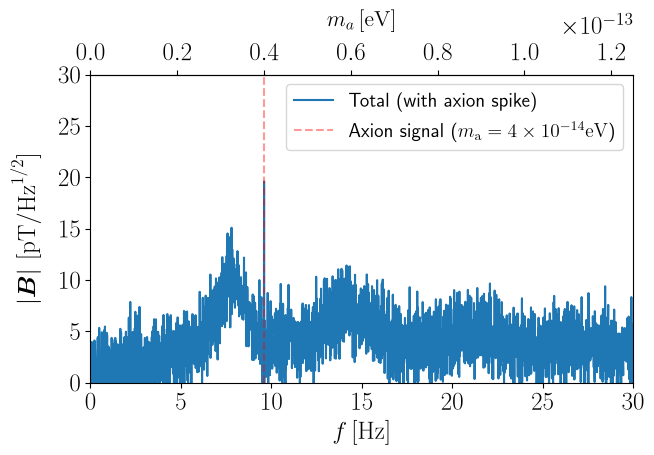

In [10]:
plt.rcParams["font.size"] = 18
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.plot(f, 1e12*np.sqrt(PSD) + noise, label="Total (with axion spike)")
ax.axvline(m2f(mass_a), color="r", ls="--", alpha=0.4, lw=1.5,
           label=r"Axion signal ($m_{\rm a}=4\times10^{-14}{\rm eV}$)")
ax.set_xlim(0, 30)
ax.set_ylim(0, 30)
ax.set_xlabel(r"$f\,[{\rm Hz}]$")
ax.set_ylabel(r"$|" + BVEC + r"|\,\,[{\rm pT/Hz}^{1/2}]$", labelpad=12)
ax2 = ax.secondary_xaxis("top", functions=(f2m, m2f))
ax2.set_xlabel(r"$m_a\,[{\rm eV}]$", size=16, labelpad=12)
ax.legend(loc="upper right", fontsize=14)
plt.show()
# save_pdf(fig, "Schematic_axion_signal.pdf")

## Fig. 2: Atmospheric conductivity profiles

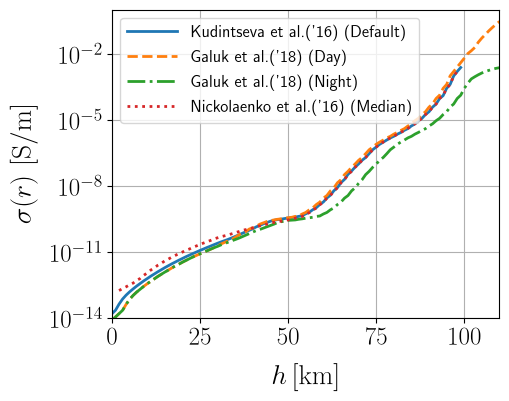

In [11]:
cmap = plt.get_cmap("tab10")
h_K,  sig_K           = sigma_kudintseva16()
h_Ni, sig_Ni          = sigma_nickolaenko16()
h_G,  sig_Gd, sig_Gn  = sigma_galuk18()

plt.rcParams["font.size"] = 18
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(111)
ax.grid()
ax.set_yscale("log")
ax.set_xlim(0, 110)
ax.set_ylim(1e-14, 1e0)
ax.set_yticks([1e-14, 1e-11, 1e-8, 1e-5, 1e-2])
ax.set_ylabel(r"$\sigma(r) \,\,{\rm[S/m]}$", size=20, labelpad=8)
ax.set_xlabel(r"$h\,{\rm[km]}$", size=20, labelpad=10)
ax.plot(h_K,  sig_K,  ls="-",  color=cmap(0), lw=2, label="Kudintseva et al.('16) (Default)")
ax.plot(h_G,  sig_Gd, ls="--", color=cmap(1), lw=2, label="Galuk et al.('18)  (Day)")
ax.plot(h_G,  sig_Gn, ls="-.", color=cmap(2), lw=2, label="Galuk et al.('18)  (Night)")
ax.plot(h_Ni, sig_Ni, ls=":",  color=cmap(3), lw=2, label="Nickolaenko et al.('16)  (Median)")
ax.legend(loc="upper left", handlelength=3., fontsize=12)
plt.show()
# save_pdf(fig, "conductivity_profiles.pdf")

## Fig. 4: Mode function $|b_\ell|$ at the Earth's surface vs axion mass

Solid lines: multi-step treatment with the default conductivity profile. Dotted lines: perfectly conducting ionosphere at $h=49.5$ km.

In [21]:
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)
h_pc = h_step[-1] / 2                                  # height of the perfect conductor [km]

mm = np.logspace(-17.0, -12, 500)                      # axion mass [eV]
ells = range(1, 7)
b_multi = {ell: np.array([mode_coeff_surface(ell, sigma_step, h_step, m, RE=R_EARTH) for m in mm]) for ell in ells}
b_pc    = {ell: np.array([mode_coeff_surface_perfect_cond(ell, h_pc, m, RE=R_EARTH) for m in mm]) for ell in ells}

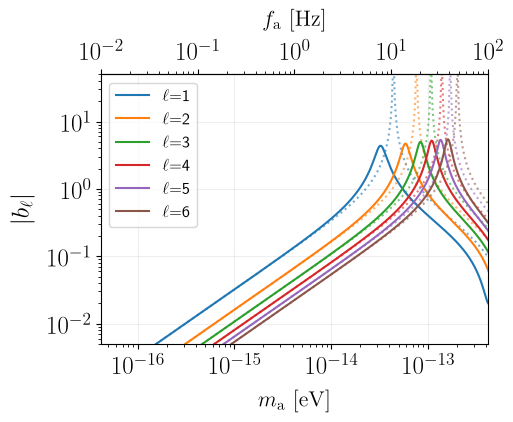

In [23]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 18
fig = plt.figure(figsize=(5, 3.5))
ax = fig.add_subplot(111)
ax.set_xlim(4.16e-17, 4.2e-13)
ax.set_ylim(5e-3, 5e1)
ax.set_xscale("log")
ax.set_yscale("log")
for ell in ells:
    ax.plot(mm, np.abs(b_multi[ell]), color=cmap(ell-1), ls="-", label=r"$\ell$={}".format(ell))
    ax.plot(mm, np.abs(b_pc[ell]),    color=cmap(ell-1), ls=":", alpha=0.6)
ax.set_xlabel(r"$m_{\rm a}\,\, [{\rm eV}]$", size=16, labelpad=8)
ax.set_ylabel(r"$|b_\ell|$", size=18, labelpad=8)
ax.legend(loc="upper left", fontsize=12)
ax.grid(alpha=0.2)
add_frequency_axis(ax, size=16)
plt.show()
# save_pdf(fig, "Mode_func_B-field.pdf")

## Fig. 5: Vertical (radial) profile of the mode function $b_\ell$

Three axion masses ($3\times10^{-15}$, $3\times10^{-14}$, $3\times10^{-13}$ eV), $\ell=1$–6. Upper panels: $|b_\ell|$. Lower panels: ${\rm Re}\,b_\ell$ (solid) and ${\rm Im}\,b_\ell$ (dashed), multiplied by the factor shown in each panel. Thin lines above the top of the profile are the extrapolation with constant conductivity.

In [24]:
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)
masses_fig5 = [3e-15, 3e-14, 3e-13]
ells = range(1, 7)
# mode_fig5[mass][ell] = (mode function, h_extra, extrapolated mode function)
mode_fig5 = {m: {ell: radial_mode_function(0, ell, sigma_step, h_step, m, RE=R_EARTH) for ell in ells}
             for m in masses_fig5}

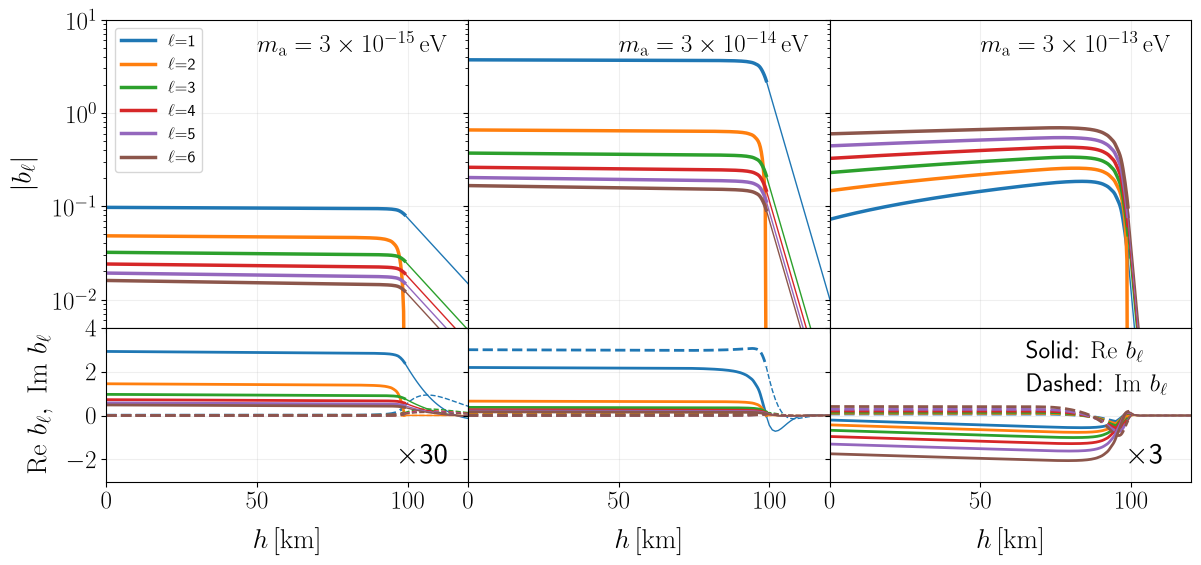

In [25]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 18
fig = plt.figure(figsize=(14, 6))
gs = gridspec.GridSpec(2, 3, wspace=0, hspace=0, height_ratios=[4, 2])

mass_labels = [r"$m_{\rm a}=3\times10^{-15} \,{\rm eV}$",
               r"$m_{\rm a}=3\times10^{-14} \,{\rm eV}$",
               r"$m_{\rm a}=3\times10^{-13} \,{\rm eV}$"]
factors = [30, 1, 3]                                   # magnification in the lower panels

for col, (mass, label, fact) in enumerate(zip(masses_fig5, mass_labels, factors)):
    # upper panel: |b_ell|
    ax = plt.subplot(gs[0, col])
    ax.tick_params(labelbottom=False, labelleft=(col == 0))
    ax.set_yscale("log")
    ax.set_xlim(0, 120)
    ax.set_ylim(5e-3, 1e1)
    ax.text(50, 4.5, label, size=18)
    ax.grid(alpha=0.2)
    if col == 0:
        ax.set_ylabel(r"$|b_\ell|$", size=20, labelpad=10)
    for ell in ells:
        f, h_extra, f_extra = mode_fig5[mass][ell]
        ax.plot(h_step,  np.abs(f),       color=cmap(ell-1), ls="-", lw=2.5, label=r"$\ell$={}".format(ell))
        ax.plot(h_extra, np.abs(f_extra), color=cmap(ell-1), ls="-", lw=1)
    if col == 0:
        ax.legend(loc="upper left", fontsize=12)

    # lower panel: Re b_ell and Im b_ell
    ax2 = plt.subplot(gs[1, col])
    ax2.tick_params(labelbottom=True, labelleft=(col == 0))
    ax2.set_xlim(0, 120)
    ax2.set_ylim(-3.01, 4.001)
    ax2.set_yticks([-2, 0, 2, 4])
    ax2.set_xlabel(r"$h\,[{\rm km}]$", size=20, labelpad=10)
    ax2.grid(alpha=0.2)
    if col == 0:
        ax2.set_ylabel(r"${\rm Re}\,\,b_\ell,\,\,{\rm Im}\,\,b_\ell$", size=20, labelpad=10)
    if fact != 1:
        ax2.text(96 if col == 0 else 98, -2.2, r"$\times$%g" % fact, size=22)
    if col == 2:
        ax2.text(65, 2.6, r"Solid:  ${\rm Re}\,\, b_\ell$", size=18)
        ax2.text(65, 1.1, r"Dashed: ${\rm Im}\,\, b_\ell$", size=18)
    for ell in ells:
        f, h_extra, f_extra = mode_fig5[mass][ell]
        ax2.plot(h_step,  fact*np.real(f),       color=cmap(ell-1), ls="-",  lw=2)
        ax2.plot(h_step,  fact*np.imag(f),       color=cmap(ell-1), ls="--", lw=2)
        ax2.plot(h_extra, fact*np.real(f_extra), color=cmap(ell-1), ls="-",  lw=1)
        ax2.plot(h_extra, fact*np.imag(f_extra), color=cmap(ell-1), ls="--", lw=1)
plt.show()
# save_pdf(fig, "mode_function_radial_profiles.pdf")

## Fig. 6: Predicted axion-induced B-field at Eskdalemuir Observatory


### Left panel: dependence on the axion mass (at the surface)

In [26]:
theta_E, phi_E = site_angles(*SITES["Eskdalemuir"])
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)

mm_fig6 = np.logspace(-17.0, -12, 800)                 # axion mass [eV]
B_E = B_surface(mm_fig6, theta_E, phi_E, h_step, sigma_step)
B_E_amp, B_E_EW, B_E_NS = horizontal_components(B_E, theta_E, phi_E)

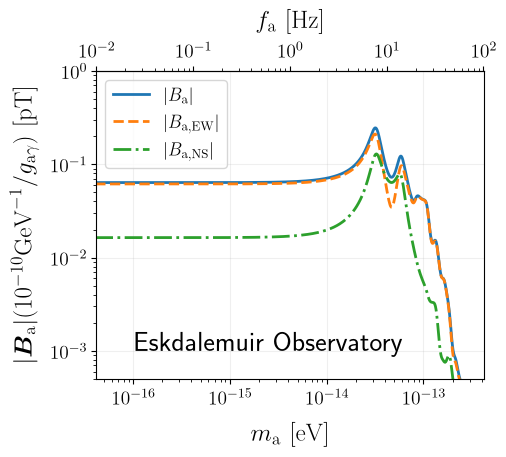

In [27]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 14
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(111)
ax.grid(alpha=0.2)
ax.set_xlim(4.16e-17, 4.2e-13)
ax.set_ylim(5e-4, 1e0)
ax.set_xlabel(r"$m_{\rm a}\,\,[{\rm eV}]$", size=18, labelpad=10)
ax.set_ylabel(r"$|" + BVEC + r"_{\rm a}| (10^{-10}{\rm GeV}^{-1}/g_{\rm a\gamma})\,\,[{\rm pT}]$", size=18, labelpad=8)
ax.plot(mm_fig6, B_E_amp, color=cmap(0), ls="-",  lw=2, label=r"$|B_{\rm a}|$")
ax.plot(mm_fig6, B_E_EW,  color=cmap(1), ls="--", lw=2, label=r"$|B_{\rm a,EW}|$")
ax.plot(mm_fig6, B_E_NS,  color=cmap(2), ls="-.", lw=2, label=r"$|B_{\rm a,NS}|$")
ax.text(1e-16, 1e-3, "Eskdalemuir Observatory", size=20)
add_frequency_axis(ax)
ax.legend(loc="upper left", fontsize=13)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()
# save_pdf(fig, "B_field_Eskdalemuir.pdf")

### Right panel: dependence on altitude

In [18]:
theta_E, phi_E = site_angles(*SITES["Eskdalemuir"])
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)

masses_fig6 = [3e-15, 3e-14, 3e-13]
prof_fig6 = {m: B_profile(m, theta_E, phi_E, h_step, sigma_step) for m in masses_fig6}

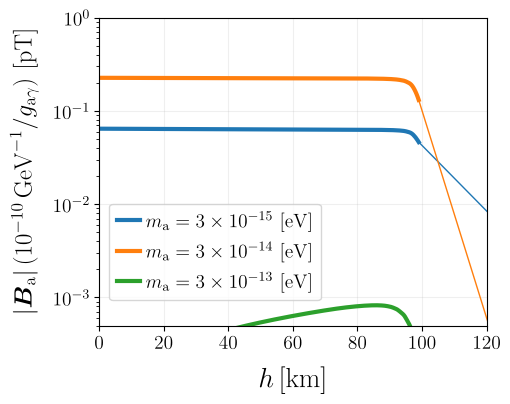

In [19]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 14
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(111)
ax.grid(alpha=0.2)
ax.set_yscale("log")
ax.set_xlim(0, 120)
ax.set_ylim(5e-4, 1e0)
ax.set_xlabel(r"$h\, [{\rm km}]$", size=20, labelpad=10)
ax.set_ylabel(r"$|" + BVEC + r"_{\rm a}|\,(10^{-10}\,{\rm GeV}^{-1}/g_{\rm a\gamma})\,\,[{\rm pT}]$", size=18, labelpad=10)
labels = [r"$m_{\rm a}=3\times10^{-15}\,\, [{\rm eV}]$",
          r"$m_{\rm a}=3\times10^{-14}\,\,[{\rm eV}]$",
          r"$m_{\rm a}=3\times10^{-13}\,\,[{\rm eV}]$"]
for i, (m, label) in enumerate(zip(masses_fig6, labels)):
    h, B, h_extra, B_extra = prof_fig6[m]
    ax.plot(h,       horizontal_components(B,       theta_E, phi_E)[0], color=cmap(i), ls="-", lw=3, label=label)
    ax.plot(h_extra, horizontal_components(B_extra, theta_E, phi_E)[0], color=cmap(i), ls="-", lw=1)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.05), fontsize=14, handlelength=1.2, handletextpad=0.3)
plt.show()
save_pdf(fig, "B-field_vertical_Eskdalemuir.pdf")

## Fig. 7: World maps of the axion-induced B-field

Color: $|{\boldsymbol B}_{\rm a}|$ [pT] at the surface. Bars: direction of the horizontal field (headless, so the sign is not shown). The three panels are for $m_{\rm a}=3\times10^{-15}$, $3\times10^{-14}$ and $3\times10^{-13}$ eV.

In [28]:
def world_map(mass, h_step, sigma_step, NX=48, NY=24, ell_max=ELL_MAX):
    """B-field on an NX x NY longitude-latitude grid.
       Returns (lon_centers, lat_centers, |B|, |B_phi|, |B_theta|) in degrees and pT."""
    lon = np.linspace(0, 360, NX)
    lat = np.linspace(-89.9, 89.9, NY)                 # avoid the poles, where Phi_lm is singular
    A = amp_axion(mass)
    b = np.zeros(ell_max + 1, dtype=complex)
    for ell in range(1, ell_max + 1):
        b[ell] = mode_coeff_surface(ell, sigma_step, h_step, mass)
    B_amp, B_phi, B_theta = (np.zeros((NY, NX)) for _ in range(3))
    for i in range(NX):
        for j in range(NY):
            theta, phi = site_angles(lat[j], lon[i])
            S = vsh_sum(theta, phi, ell_max)
            B = -1j * A * (b @ S)
            B_amp[j, i]   = np.sqrt(np.abs(B @ np.conjugate(B)))
            B_phi[j, i]   = np.abs(B @ ephi(theta, phi))
            B_theta[j, i] = np.abs(B @ etheta(theta, phi))
    return lon, lat, B_amp, B_phi, B_theta


def plot_world_map(lon, lat, B_amp, B_phi, B_theta, title, vmax):
    NX, NY = lon.size, lat.size
    # cell edges for pcolormesh
    lon_edges = np.linspace(lon[0] - (lon[-1]-lon[0])/(2*NX), lon[-1] + (lon[-1]-lon[0])/(2*NX), NX+1)
    lat_edges = np.linspace(lat[0] - (lat[-1]-lat[0])/(2*NY), lat[-1] + (lat[-1]-lat[0])/(2*NY), NY+1)

    plt.rcParams["font.size"] = 18
    fig = plt.figure(figsize=(10, 4))
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines(lw=0.5)
    ax.set_xticks(np.arange(0, 360.1, 60), crs=ccrs.PlateCarree())
    ax.set_yticks(np.arange(-90, 90.1, 30), crs=ccrs.PlateCarree())
    deg = r"$^{\circ}$" if USE_TEX else "°"            # the Unicode degree sign fails on some TeX setups
    ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True, degree_symbol=deg))
    ax.yaxis.set_major_formatter(LatitudeFormatter(degree_symbol=deg))
    ax.tick_params(labelsize=14)
    ax.set_title(title, fontsize=18)

    LON_E, LAT_E = np.meshgrid(lon_edges - 180.0, lat_edges)
    cf = ax.pcolormesh(LON_E, LAT_E, B_amp, cmap="plasma", vmin=0, vmax=vmax)
    cb = fig.colorbar(cf, ax=ax, orientation="vertical", shrink=0.8, pad=0.01)
    cb.set_label(r"${\rm pT}$", fontsize=18)

    LON, LAT = np.meshgrid(lon - 180.0, lat)
    ax.quiver(LON, LAT, B_phi, B_theta, pivot="mid", units="xy", width=0.7,
              headwidth=0, headlength=0, headaxislength=0)
    return fig

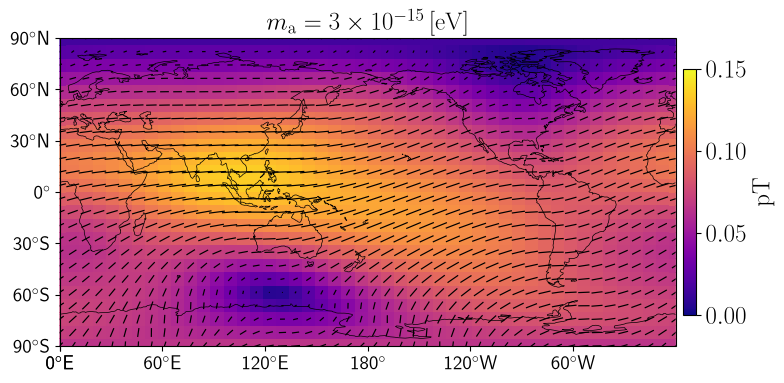

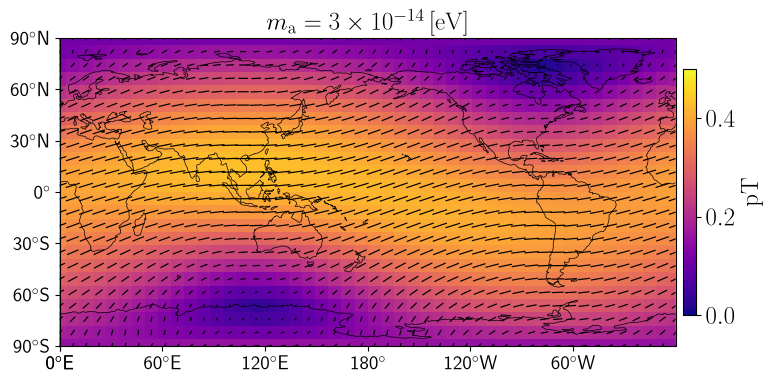

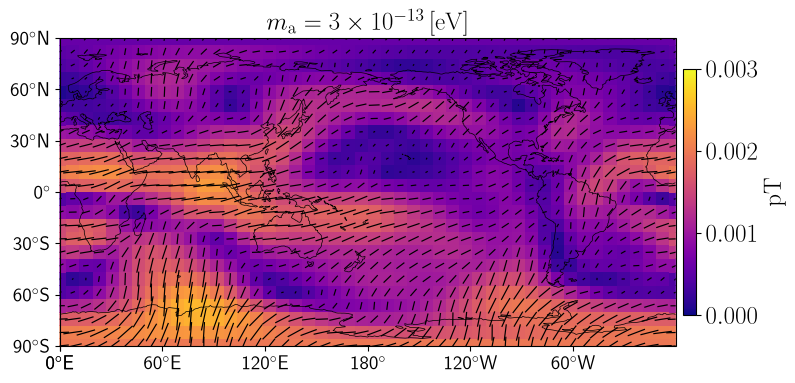

In [29]:
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)

# (axion mass [eV], panel title, upper limit of the color scale [pT], PDF file name)
panels_fig7 = [
    (3e-15, r"$m_{\rm a}=3\times10^{-15}\,[{\rm eV}]$", 0.15,  "world_map_B_field_3e-15.pdf"),
    (3e-14, r"$m_{\rm a}=3\times10^{-14}\,[{\rm eV}]$", 0.5,   "world_map_B_field_3e-14.pdf"),
    (3e-13, r"$m_{\rm a}=3\times10^{-13}\,[{\rm eV}]$", 0.003, "world_map_B_field_3e-13.pdf"),
]

if HAS_CARTOPY:
    for mass, title, vmax, fname in panels_fig7:
        fig = plot_world_map(*world_map(mass, h_step, sigma_step), title=title, vmax=vmax)
        plt.show()
        # save_pdf(fig, fname)
else:
    print("Fig. 7 skipped (cartopy is not installed).")

## Fig. 8: Axion-induced B-field at three extreme sites

North magnetic pole, south magnetic pole, and Singapore (near the magnetic equator).

In [30]:
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)
mm_fig8 = np.logspace(-17.0, -12, 300)                 # axion mass [eV]

sites_fig8 = [("North_pole", "North magnetic pole"),
              ("South_pole", "South magnetic pole"),
              ("Singapore",  "Merlion park (Singapore)")]
B_fig8 = {}
for key, _ in sites_fig8:
    theta, phi = site_angles(*SITES[key])
    B_fig8[key] = horizontal_components(B_surface(mm_fig8, theta, phi, h_step, sigma_step), theta, phi)

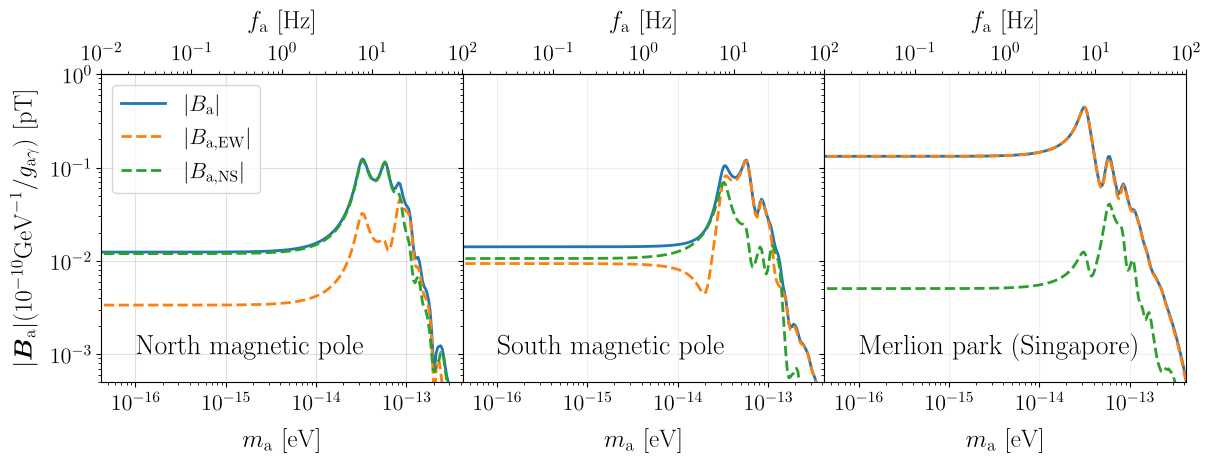

In [23]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 16
fig = plt.figure(figsize=(14, 4))
plt.subplots_adjust(wspace=0)
for i, (key, label) in enumerate(sites_fig8):
    B_amp, B_EW, B_NS = B_fig8[key]
    ax = fig.add_subplot(1, 3, i+1)
    ax.tick_params(labelbottom=True, labelleft=(i == 0))
    ax.grid(alpha=0.4 if i == 0 else 0.2)
    ax.set_xlim(4.16e-17 if i == 0 else 4.18e-17, 4.2e-13)
    ax.set_ylim(5e-4, 1e0)
    ax.set_xlabel(r"$m_{\rm a}\,\, [{\rm eV}]$", size=18, labelpad=10)
    if i == 0:
        ax.set_ylabel(r"$|" + BVEC + r"_{\rm a}| (10^{-10}{\rm GeV}^{-1}/g_{\rm a\gamma})\,\,[{\rm pT}]$", size=18, labelpad=8)
    ax.plot(mm_fig8, B_amp, color=cmap(0), ls="-",  lw=2, label=r"$|B_{\rm a}|$")
    ax.plot(mm_fig8, B_EW,  color=cmap(1), ls="--", lw=2, label=r"$|B_{\rm a,EW}|$")
    ax.plot(mm_fig8, B_NS,  color=cmap(2), ls="--", lw=2, label=r"$|B_{\rm a,NS}|$")
    ax.text(1e-16, 1e-3, label, size=20)
    add_frequency_axis(ax)
    if i == 0:
        ax.legend(loc="upper left", fontsize=16)
    ax.set_xscale("log")
    ax.set_yscale("log")
plt.show()
# save_pdf(fig, "B_field_representative.pdf")

## Fig. 9: Dependence on the conductivity profile and on the upper boundary condition

At Eskdalemuir. The reference model is Kudintseva et al. with constant conductivity above the top of the profile ("Default"). It is compared with:

* Kudintseva et al. with an exponential profile above the top, whose scale height $\zeta$ is set by the gradient at the top of the table ("Exponential")
* Galuk et al. (day and night)
* Nickolaenko et al. (median)

The lower panels show the fractional difference from the reference model.

In [31]:
num_step = 300
h_K,  sig_K          = sigma_kudintseva16()
h_Ni, sig_Ni         = sigma_nickolaenko16()
h_G,  sig_Gd, sig_Gn = sigma_galuk18()

zeta_K = exp_scale_height(h_K, sig_K)                  # = 2.9225 km

# label -> (h_step, sigma_step, zeta, color index of tab20, line style)
models_fig9 = {
    "Kudintseva et al.('16) (Default)":     (*step_profile(h_K,  sig_K,  num_step), None,   0, "-"),
    "Kudintseva et al.('16) (Exponential)": (*step_profile(h_K,  sig_K,  num_step), zeta_K, 1, "-"),
    "Galuk et al.('18) (Day)":              (*step_profile(h_G,  sig_Gd, num_step), None,   2, "--"),
    "Galuk et al.('18) (Night)":            (*step_profile(h_G,  sig_Gn, num_step), None,   4, "-."),
    "Nickolaenko et al.('16) (Median)":     (*step_profile(h_Ni, sig_Ni, num_step), None,   6, ":"),
}
REF = "Kudintseva et al.('16) (Default)"
theta_E, phi_E = site_angles(*SITES["Eskdalemuir"])
print(f"zeta (Kudintseva et al.) = {zeta_K:.4f} km")

zeta (Kudintseva et al.) = 2.9225 km


### Left panel: dependence on the axion mass (at the surface)

In [32]:
mm_fig9 = np.logspace(-17.0, -12, 300)                 # axion mass [eV]
Bamp_fig9 = {}
for label, (h_step, sigma_step, zeta, _, _) in models_fig9.items():
    B = B_surface(mm_fig9, theta_E, phi_E, h_step, sigma_step, zeta=zeta)
    Bamp_fig9[label] = np.sqrt(np.sum(np.abs(B)**2, axis=1))

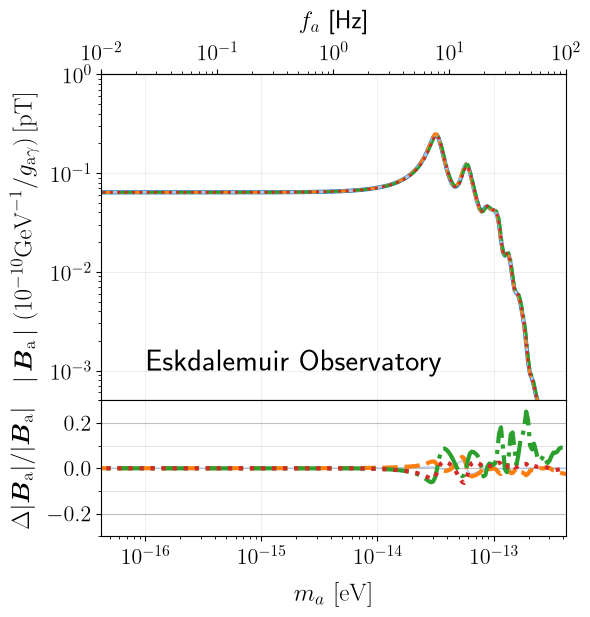

In [33]:
cmap = plt.get_cmap("tab20")
plt.rcParams["font.size"] = 16
fig = plt.figure(figsize=(6, 6))
gs = gridspec.GridSpec(2, 1, hspace=0, height_ratios=[3, 1.25])

ax = plt.subplot(gs[0, 0])
ax.set_xlim(4.16e-17, 4.2e-13)
ax.set_ylim(5e-4, 1e0)
ax.set_ylabel(r"$|\," + BVEC + r"_{\rm a}\,|\,\,(10^{-10}{\rm GeV}^{-1}/g_{\rm a\gamma})\,{\rm[pT]}$", size=18, labelpad=8)
for label, (_, _, _, c, ls) in models_fig9.items():
    ax.plot(mm_fig9, Bamp_fig9[label], color=cmap(c), lw=3 if label == REF else 2, ls=ls, label=label)
ax.text(1e-16, 1e-3, "Eskdalemuir Observatory", size=22)
ax.grid(alpha=0.2)
ax2 = ax.secondary_xaxis("top", functions=(m2f, f2m))
ax2.set_xlabel(r"$f_a$ [Hz]", size=18, labelpad=10)
ax.set_xscale("log")
ax.set_yscale("log")

bx = plt.subplot(gs[1, 0])
bx.set_xlim(4.16e-17, 4.2e-13)
bx.set_ylim(-0.3, 0.3)
bx.set_xlabel(r"$m_a\,\, [{\rm eV}]$", size=18, labelpad=10)
bx.set_ylabel(r"$\Delta|" + BVEC + r"_{\rm a}|/|" + BVEC + r"_{\rm a}|$", size=18, labelpad=8)
for label, (_, _, _, c, ls) in models_fig9.items():
    if label != REF:
        bx.plot(mm_fig9, Bamp_fig9[label]/Bamp_fig9[REF] - 1, color=cmap(c), lw=1 if c == 1 else 3, ls=ls)
bx.set_xscale("log")
bx.yaxis.set_major_locator(MultipleLocator(0.2))
bx.yaxis.set_minor_locator(MultipleLocator(0.1))
bx.yaxis.grid(True, which="major", ls="-", lw=0.8, alpha=0.8)
bx.yaxis.grid(True, which="minor", ls="-", lw=0.5, alpha=0.5)
bx.xaxis.grid(True, alpha=0.2)
plt.show()
# save_pdf(fig, "B-field_Eskdalemuir_model_dependence_mass.pdf")

### Right panel: dependence on altitude ($m_{\rm a}=3\times10^{-14}$ eV)

In [34]:
mass_fig9 = 3e-14
prof_fig9 = {}   # label -> (h, |B|) including the extrapolation above the top of the profile
for label, (h_step, sigma_step, zeta, _, _) in models_fig9.items():
    h, B, h_extra, B_extra = B_profile(mass_fig9, theta_E, phi_E, h_step, sigma_step, zeta=zeta)
    prof_fig9[label] = (h, horizontal_components(B, theta_E, phi_E)[0],
                        h_extra, horizontal_components(B_extra, theta_E, phi_E)[0])

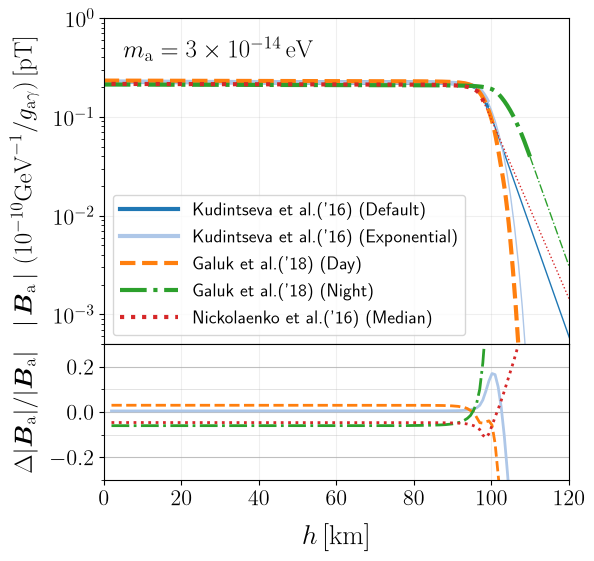

In [35]:
cmap = plt.get_cmap("tab20")
plt.rcParams["font.size"] = 16
fig = plt.figure(figsize=(6, 6))
gs = gridspec.GridSpec(2, 1, hspace=0, height_ratios=[3, 1.25])

ax = plt.subplot(gs[0, 0])
ax.tick_params(labelbottom=False)
ax.grid(alpha=0.2)
ax.set_yscale("log")
ax.set_xlim(0, 120)
ax.set_ylim(5e-4, 1)
ax.set_ylabel(r"$|\," + BVEC + r"_{\rm a}\,|\,\,(10^{-10}{\rm GeV}^{-1}/g_{\rm a\gamma})\,{\rm[pT]}$", size=18, labelpad=10)
ax.text(5, 0.4, r"$m_{\rm a}=3\times10^{-14}\,{\rm eV}$", size=18)
for label, (_, _, _, c, ls) in models_fig9.items():
    h, B, h_extra, B_extra = prof_fig9[label]
    ax.plot(h,       B,       color=cmap(c), ls=ls, lw=3, label=label)
    ax.plot(h_extra, B_extra, color=cmap(c), ls=ls, lw=1)
ax.legend(loc="lower left", handlelength=3.2, fontsize=13)

# fractional difference from the reference model, interpolated on a common grid
absB = {label: interp1d(np.append(h, h_extra), np.append(B, B_extra))
        for label, (h, B, h_extra, B_extra) in prof_fig9.items()}
hhint = np.linspace(h_Ni[0], 120, 150)                 # common range of all the models

bx = plt.subplot(gs[1, 0])
bx.set_xlim(0, 120)
bx.set_ylim(-0.3, 0.3)
bx.set_xlabel(r"$h\, {\rm [km]}$", size=20, labelpad=10)
bx.set_ylabel(r"$\Delta|" + BVEC + r"_{\rm a}|/|" + BVEC + r"_{\rm a}|$", size=18, labelpad=8)
for label, (_, _, _, c, ls) in models_fig9.items():
    if label != REF:
        bx.plot(hhint, absB[label](hhint)/absB[REF](hhint) - 1, color=cmap(c), lw=2, ls=ls)
bx.yaxis.set_major_locator(MultipleLocator(0.2))
bx.yaxis.set_minor_locator(MultipleLocator(0.1))
bx.yaxis.grid(True, which="major", ls="-", lw=0.8, alpha=0.8)
bx.yaxis.grid(True, which="minor", ls="-", lw=0.5, alpha=0.5)
bx.xaxis.grid(True, alpha=0.2)
plt.show()
# save_pdf(fig, "B-field_Eskdalemuir_model_dependence_profile.pdf")